# Estadística descriptiva

## Entorno

Importé las librerías y fijé la semilla 42, que usan la partición y todos los modelos. Sin semilla,
K-Means y GMM arrancan desde centroides o componentes distintos en cada corrida, así que los grupos, su
numeración y las métricas cambiarían, y nadie podría verificar las cifras del informe. También imprimí
las versiones de Python, NumPy, pandas, scikit-learn y Matplotlib, porque los valores por defecto de los
estimadores cambian de una versión a otra y con ellos los resultados.

Definí tres funciones auxiliares. La función redondear aplica redondeo mitad hacia arriba una sola vez
sobre el valor completo. La usé en todas las cifras que se guardan porque round de Python trabaja sobre
la representación binaria y, por ejemplo, redondea 0,2175 a 0,217, mientras que el informe diría 0,218.
Así cada número se ve igual en el notebook y en el informe. La función guardar escribe la figura en
splits antes de mostrarla, porque plt.show libera la figura y el archivo saldría en blanco. La función
guardar_resultados agrega las cifras de cada notebook a resultados.json, de donde las toma el informe sin
copiarlas a mano.

In [1]:
import os, time, json, platform, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import joblib
from decimal import Decimal, ROUND_HALF_UP

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 40)
plt.rcParams['figure.dpi'] = 100
SEMILLA = 42
np.random.seed(SEMILLA)

EN_DRIVE = False
try:
    from google.colab import drive
    drive.mount('/content/drive')
    if not os.path.isdir('/content/drive/MyDrive'):
        raise RuntimeError('Drive no quedó montado. Vuelve a ejecutar esta celda y autoriza el acceso '
                           'en la ventana emergente.')
    RUTA = '/content/drive/MyDrive/credit_card'
    EN_DRIVE = True
except ImportError:
    RUTA = os.path.abspath('..' if os.path.basename(os.getcwd()) == 'notebooks' else '.')

CARPETA_SPLITS = os.path.join(RUTA, 'splits')
os.makedirs(CARPETA_SPLITS, exist_ok=True)
ARCHIVO_RESULTADOS = os.path.join(RUTA, 'resultados.json')
resultados = {}
if os.path.exists(ARCHIVO_RESULTADOS):
    with open(ARCHIVO_RESULTADOS, encoding='utf-8') as f:
        resultados = json.load(f)

def redondear(valor, decimales=3):
    r = Decimal(repr(float(valor))).quantize(Decimal(1).scaleb(-decimales), rounding=ROUND_HALF_UP)
    return int(r) if decimales == 0 else float(r)

def redondear_serie(serie, decimales=3):
    return serie.map(lambda v: redondear(v, decimales))

def guardar(nombre):
    plt.tight_layout()
    plt.savefig(os.path.join(CARPETA_SPLITS, nombre + '.png'), dpi=150, bbox_inches='tight', facecolor='white')
    print('Gráfico guardado:', nombre + '.png')
    plt.show()

def guardar_resultados():
    with open(ARCHIVO_RESULTADOS, 'w', encoding='utf-8') as f:
        json.dump(resultados, f, ensure_ascii=False, indent=1,
                  default=lambda o: o.item() if hasattr(o, 'item') else str(o))
    print('Cifras guardadas en resultados.json')

resultados['versiones'] = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
                           'scikit-learn': sklearn.__version__, 'matplotlib': matplotlib.__version__}
print('Guardando en Google Drive' if EN_DRIVE else 'Google Drive no disponible, guardando localmente')
print('Versiones:', resultados['versiones'])

Google Drive no disponible, guardando localmente
Versiones: {'python': '3.12.10', 'numpy': '2.2.6', 'pandas': '3.0.3', 'scikit-learn': '1.8.0', 'matplotlib': '3.10.9'}


## Carga de los datos

Leí la copia local CC_GENERAL.csv si ya existía y, si no, descargué el conjunto arjunbhasin2013/ccdata de
Kaggle con kagglehub, que no pide credenciales para datos públicos. Guardar la copia evita descargarlo en
cada notebook y asegura que los seis trabajen sobre el mismo archivo.

In [2]:
warnings.filterwarnings('ignore', message='IProgress not found')
import kagglehub

ARCHIVO_LOCAL = os.path.join(RUTA, 'CC_GENERAL.csv')

def cargar_datos():
    if os.path.exists(ARCHIVO_LOCAL):
        return pd.read_csv(ARCHIVO_LOCAL)
    carpeta = kagglehub.dataset_download('arjunbhasin2013/ccdata')
    datos = pd.read_csv(os.path.join(carpeta, 'CC GENERAL.csv'))
    datos.to_csv(ARCHIVO_LOCAL, index=False)
    return datos

datos = cargar_datos()
print('Filas:', datos.shape[0], '| Columnas:', datos.shape[1])

Filas: 8950 | Columnas: 18


El análisis usa solo clientes de entrenamiento, para que ninguna decisión de preprocesamiento se tome
mirando a los de prueba. Por eso repetí el recorte de proporciones y la partición del notebook 03, con el
mismo 80 por ciento y la misma semilla, así que los 7 160 clientes son exactamente los mismos.

In [3]:
from sklearn.model_selection import train_test_split

frecuencias = [c for c in datos.columns if 'FREQUENCY' in c or c == 'PRC_FULL_PAYMENT']
X = datos.drop(columns='CUST_ID').copy()
X[frecuencias] = X[frecuencias].clip(upper=1)
X_train, _ = train_test_split(X, test_size=0.2, random_state=SEMILLA)
MONTOS = ['BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE',
          'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS']
print('Clientes de entrenamiento:', len(X_train))

Clientes de entrenamiento: 7160


## Escalas y distribuciones

Medí la dispersión de cada variable con la desviación estándar muestral y la forma con el coeficiente de
asimetría que calcula pandas con skew, el de Fisher-Pearson ajustado por el tamaño de la muestra. Vale 0
en una distribución simétrica, es positivo cuando la cola larga está a la derecha, y a partir de 1 en
valor absoluto la asimetría ya se considera fuerte. También medí la masa puntual, el porcentaje de
clientes que comparten el valor más repetido de cada variable. Muchos puntos idénticos no molestan a
K-Means, pero a GMM le permiten ajustar una gaussiana de varianza casi nula sobre ese valor. Las tres
medidas deciden el preprocesamiento. Una asimetría fuerte pide una transformación logarítmica, una escala
muy distinta entre variables obliga a escalar y una masa puntual grande avisa que GMM va a necesitar
regularización.

Desviación estándar máxima: 3662 CREDIT_LIMIT
Desviación estándar mínima: 0.2 CASH_ADVANCE_FREQUENCY


Gráfico guardado: 02_histogramas.png


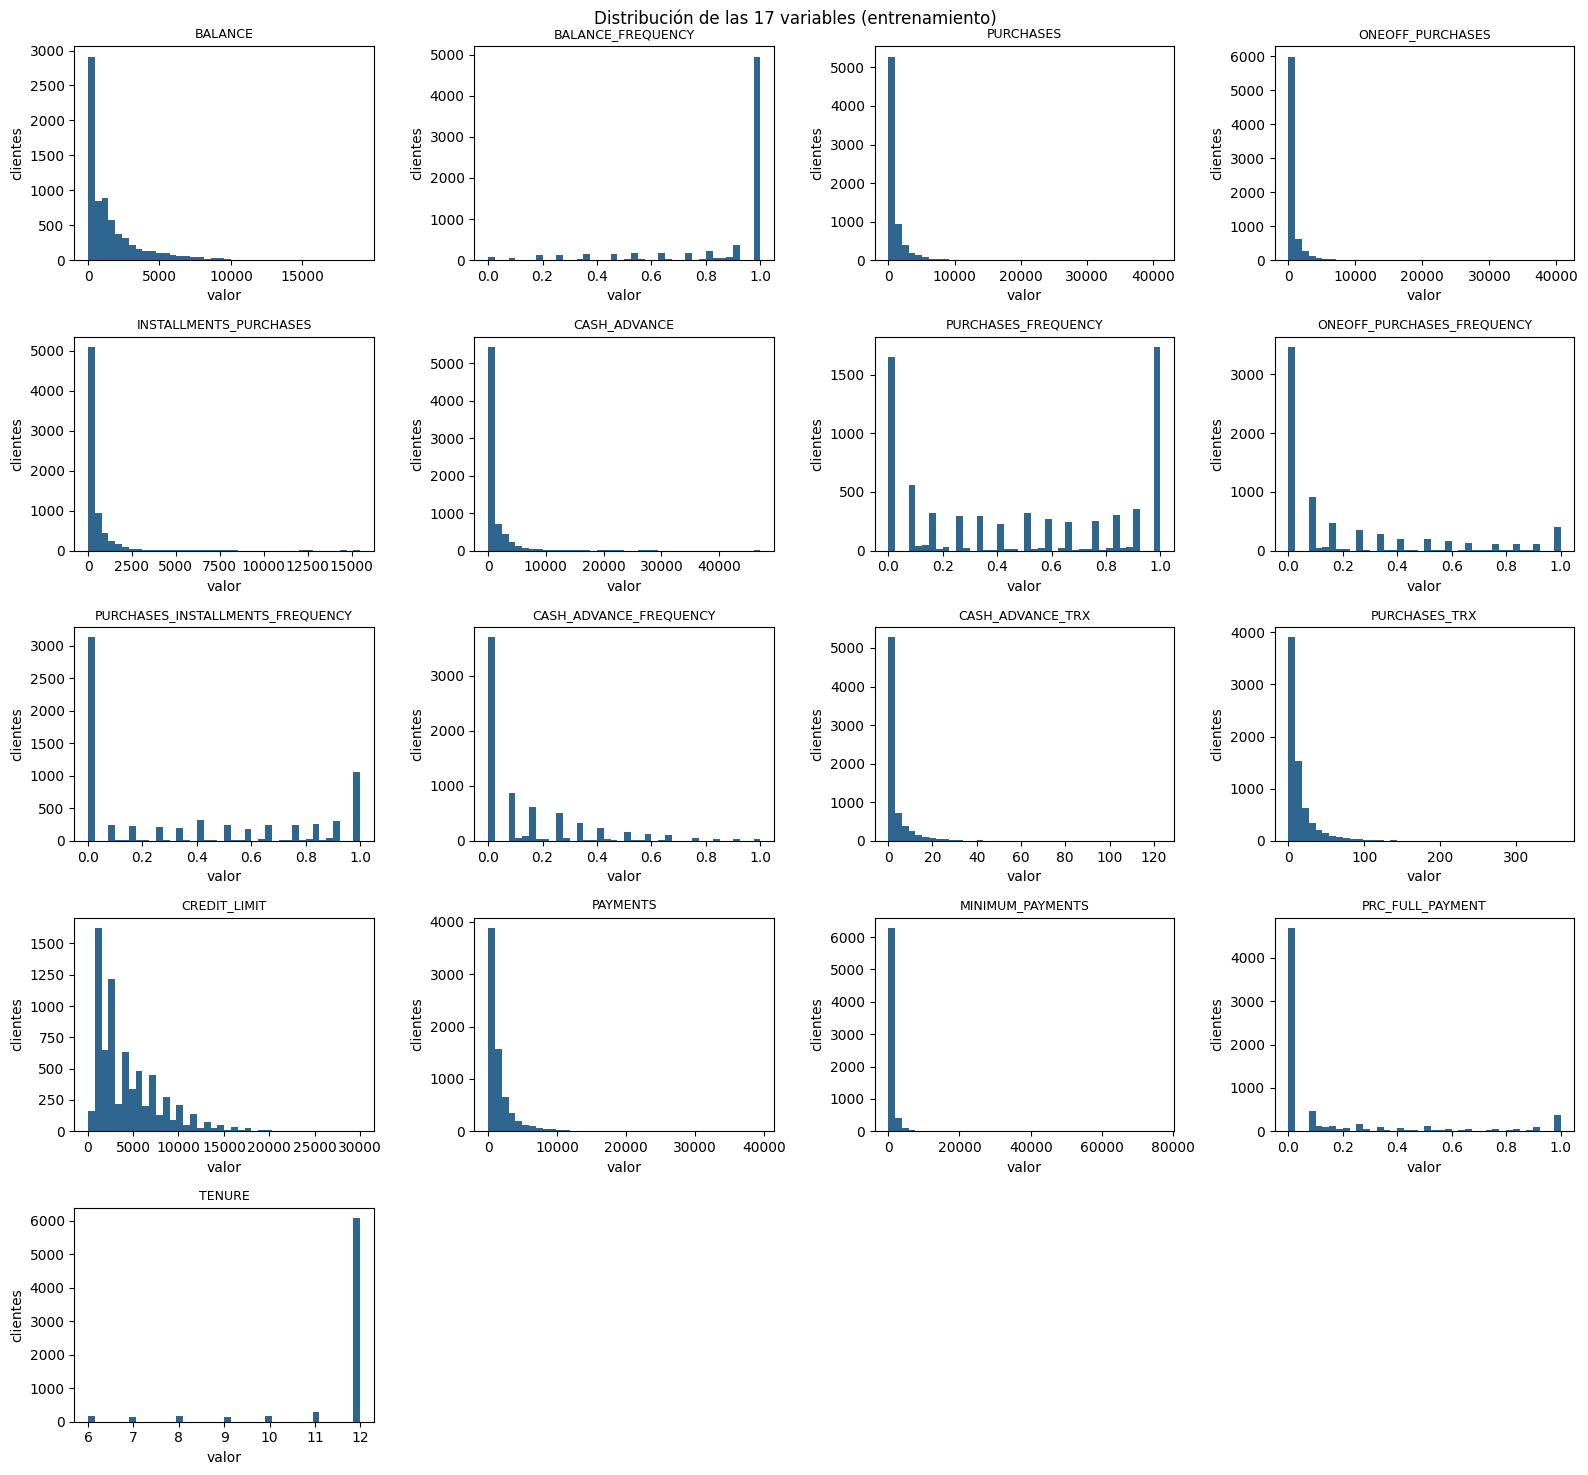

In [4]:
desv = X_train.std().sort_values(ascending=False)
print('Desviación estándar máxima:', redondear(desv.iloc[0], 0), desv.index[0])
print('Desviación estándar mínima:', redondear(desv.iloc[-1], 2), desv.index[-1])
resultados['escala'] = {'max': [desv.index[0], redondear(desv.iloc[0], 0)], 'min': [desv.index[-1], redondear(desv.iloc[-1], 2)]}

fig, ax = plt.subplots(5, 4, figsize=(16, 15))
for a, c in zip(ax.flat, X_train.columns):
    a.hist(X_train[c].dropna(), bins=40, color='#2f6690')
    a.set_title(c, fontsize=9)
    a.set_xlabel('valor')
    a.set_ylabel('clientes')
for a in ax.flat[len(X_train.columns):]:
    a.axis('off')
fig.suptitle('Distribución de las 17 variables (entrenamiento)')
guardar('02_histogramas')

El límite de crédito tuvo una desviación estándar de 3 662, mientras que la frecuencia de avances en
efectivo tuvo una de 0,20. Sin escalar, cualquier distancia quedaría dominada por los montos y las
frecuencias no contarían. Los histogramas muestran que casi todos los montos se amontonan cerca de cero
con una cola larga a la derecha, y que varias variables tienen una barra dominante en un único valor.

In [5]:
from sklearn.preprocessing import QuantileTransformer

cuantiles = QuantileTransformer(output_distribution='normal', n_quantiles=1000, random_state=SEMILLA)
X_cuantiles = pd.DataFrame(cuantiles.fit_transform(X_train[MONTOS].fillna(X_train[MONTOS].median())), columns=MONTOS, index=X_train.index)
asimetria = pd.DataFrame({'asimetría original': X_train[MONTOS].skew(),
                          'asimetría con log1p': np.log1p(X_train[MONTOS]).skew(),
                          'asimetría con cuantiles': X_cuantiles.skew()}).apply(lambda c: redondear_serie(c, 2))
resultados['asimetria'] = asimetria.to_dict(orient='index')
masa = redondear_serie(X_train.apply(lambda s: s.value_counts(normalize=True).iloc[0]) * 100, 1).sort_values(ascending=False)
resultados['masa_puntual'] = masa.to_dict()
print('=== Porcentaje de clientes en el valor más repetido de cada variable ===')
print(masa.to_string())
asimetria

=== Porcentaje de clientes en el valor más repetido de cada variable ===
TENURE                              84.8
BALANCE_FREQUENCY                   69.2
PRC_FULL_PAYMENT                    65.5
CASH_ADVANCE_TRX                    51.7
CASH_ADVANCE                        51.7
CASH_ADVANCE_FREQUENCY              51.7
ONEOFF_PURCHASES_FREQUENCY          48.4
ONEOFF_PURCHASES                    48.4
INSTALLMENTS_PURCHASES              43.7
PURCHASES_INSTALLMENTS_FREQUENCY    43.7
PURCHASES_FREQUENCY                 24.2
PURCHASES_TRX                       23.0
PURCHASES                           23.0
CREDIT_LIMIT                         8.6
PAYMENTS                             2.8
BALANCE                              0.9
MINIMUM_PAYMENTS                     0.0


,asimetría original,asimetría con log1p,asimetría con cuantiles
BALANCE,2.42,-0.85,-0.78
PURCHASES,7.81,-0.76,-1.02
ONEOFF_PURCHASES,9.85,0.20,0.00
INSTALLMENTS_PURCHASES,6.33,-0.03,-0.17
CASH_ADVANCE,5.42,0.26,0.13
CASH_ADVANCE_TRX,6.02,0.96,0.13
PURCHASES_TRX,4.83,0.04,-1.02
CREDIT_LIMIT,1.46,-0.12,0.03
PAYMENTS,5.41,-1.79,-1.56
MINIMUM_PAYMENTS,14.11,0.25,-0.02


Los diez montos y conteos fueron muy asimétricos, con coeficientes entre 1,46 y 14,11. Después de aplicar
log1p la asimetría bajó a valores entre menos 1,79 y 0,96, con PAYMENTS todavía en menos 1,79 y
CASH_ADVANCE_TRX en 0,96. Con la transformación por cuantiles quedó entre menos 1,56 y 0,13. Lo que queda
de asimetría viene de los bloques de clientes con el mismo valor, como los que nunca compraron, que
ninguna transformación monótona puede repartir. Elegí la transformación por cuantiles para el
preprocesamiento del notebook 03 porque acota los dos extremos y trata igual a todas las variables. Más
importante para el modelado fue la concentración en un solo valor. El 84,8 por ciento de los clientes
tiene 12 meses de antigüedad, el 69,2 por ciento tiene BALANCE_FREQUENCY igual a 1, el 65,5 por ciento
nunca pagó el total de su deuda y el 51,7 por ciento nunca retiró efectivo. Estas masas puntuales no son
errores sino conductas reales, pero condicionaron el ajuste de GMM en el notebook 04.

## Atípicos

Conté los valores atípicos con la regla del rango intercuartílico (por debajo de Q1 menos 1,5 veces el
rango o por encima de Q3 más 1,5 veces el rango) y comparé los montos antes y después de la
transformación por cuantiles. Los atípicos importan porque K-Means representa cada grupo con una media,
que se desplaza hacia los valores extremos, y GMM puede dedicar una componente entera a unos pocos
clientes extremos. Quise saber cuántos son antes de decidir si eliminarlos o reducir su influencia.

=== Atípicos por variable (regla IQR) ===
BALANCE_FREQUENCY             1190
PRC_FULL_PAYMENT              1182
TENURE                        1087
ONEOFF_PURCHASES               828
CASH_ADVANCE                   827
ONEOFF_PURCHASES_FREQUENCY     741
INSTALLMENTS_PURCHASES         694
MINIMUM_PAYMENTS               663
PURCHASES                      661
PAYMENTS                       646
CASH_ADVANCE_TRX               644
PURCHASES_TRX                  602
BALANCE                        555
CASH_ADVANCE_FREQUENCY         424
CREDIT_LIMIT                   201 

Clientes con al menos un valor atípico: 67.0 por ciento


Gráfico guardado: 02_atipicos.png


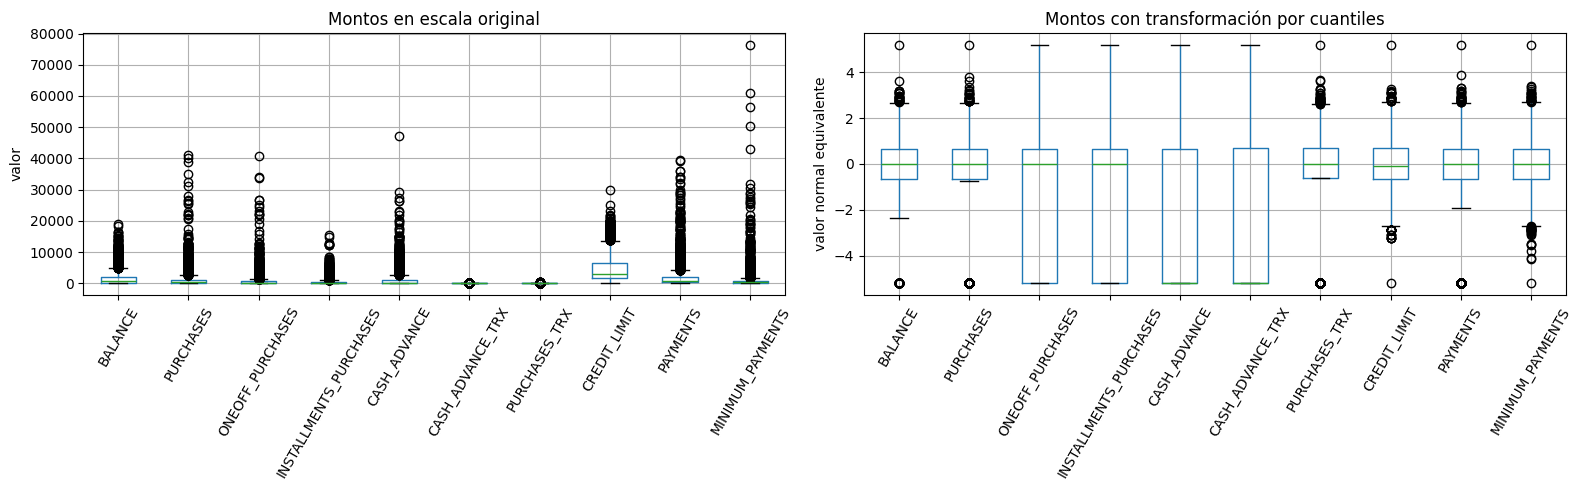

In [6]:
q1, q3 = X_train.quantile(0.25), X_train.quantile(0.75)
iqr = q3 - q1
fuera = (X_train < q1 - 1.5 * iqr) | (X_train > q3 + 1.5 * iqr)
atipicos = fuera.sum().sort_values(ascending=False)
pct_filas = redondear(fuera.any(axis=1).mean() * 100, 1)
print('=== Atípicos por variable (regla IQR) ===')
print(atipicos[atipicos > 0].to_string(), '\n')
print('Clientes con al menos un valor atípico:', pct_filas, 'por ciento')
resultados['atipicos'] = {k: int(v) for k, v in atipicos[atipicos > 0].items()}
resultados['pct_filas_atipicas'] = pct_filas

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
X_train[MONTOS].boxplot(ax=ax[0], rot=60)
ax[0].set_title('Montos en escala original')
ax[0].set_ylabel('valor')
X_cuantiles.boxplot(ax=ax[1], rot=60)
ax[1].set_title('Montos con transformación por cuantiles')
ax[1].set_ylabel('valor normal equivalente')
guardar('02_atipicos')

El 67 por ciento de los clientes tuvo al menos un valor atípico. La cifra está inflada por las masas
puntuales, porque en TENURE, BALANCE_FREQUENCY o PRC_FULL_PAYMENT el rango intercuartílico se achica
tanto que cualquier valor distinto del dominante cae fuera. En los montos los atípicos sí son clientes
que gastan, deben o retiran mucho más que el resto. No los eliminé porque son justamente los clientes que
más le importan al banco, tanto por su valor como por su riesgo. En cambio reduje su influencia con la
transformación por cuantiles, que reemplaza cada valor por su posición en la distribución y acota la cola
larga, como muestra el segundo panel.

## Correlaciones

Usé el coeficiente de Pearson, r = cov(X, Y) / (σ_X σ_Y), sobre las variables de entrenamiento sin
transformar. Mide asociación lineal entre menos 1 y 1. Marqué los pares con correlación absoluta de 0,7 o
más, porque dos variables tan correlacionadas cuentan casi la misma información dos veces dentro de una
distancia euclidiana, y eso le da a esa dimensión de uso más peso del que le corresponde.

Gráfico guardado: 02_correlacion.png


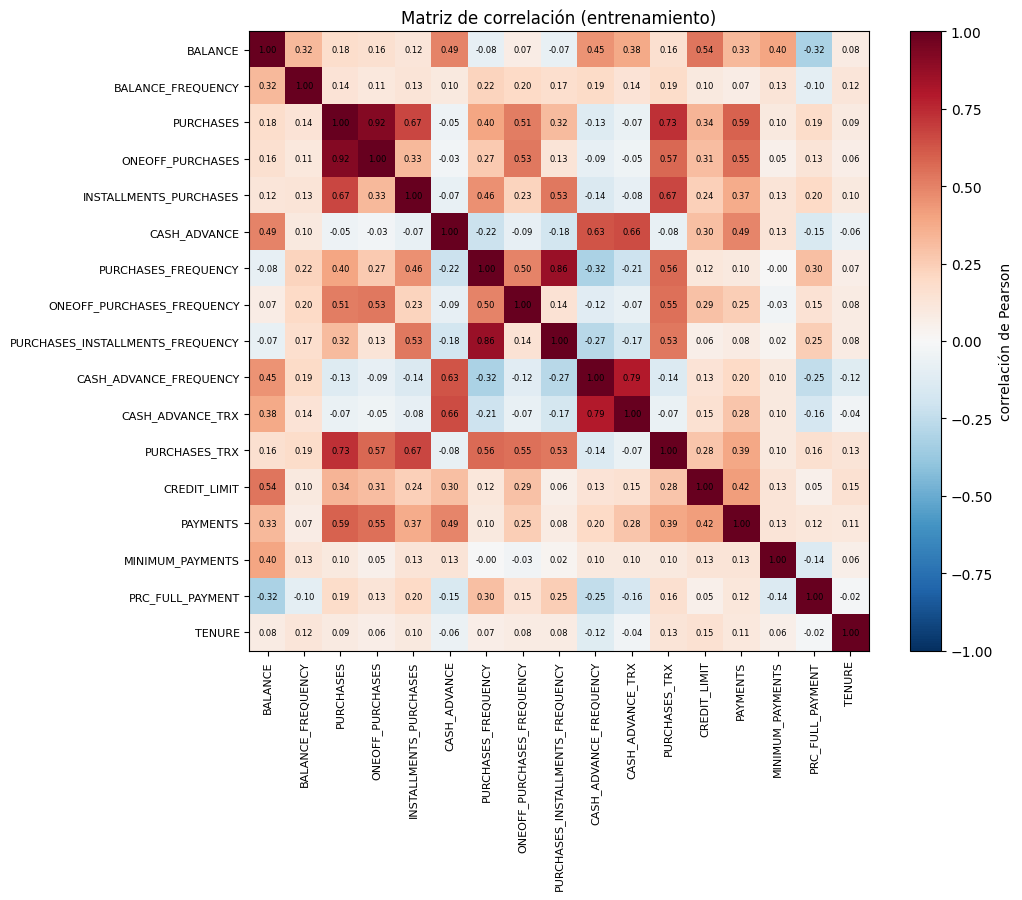

=== Pares con correlación absoluta de 0,7 o más ===
PURCHASES               ONEOFF_PURCHASES                    0.92
PURCHASES_FREQUENCY     PURCHASES_INSTALLMENTS_FREQUENCY    0.86
CASH_ADVANCE_FREQUENCY  CASH_ADVANCE_TRX                    0.79
PURCHASES               PURCHASES_TRX                       0.73


In [7]:
corr = X_train.corr()
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=6)
fig.colorbar(im, label='correlación de Pearson')
ax.set_title('Matriz de correlación (entrenamiento)')
guardar('02_correlacion')

pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
fuertes = pares[pares.abs() >= 0.7].sort_values(ascending=False)
print('=== Pares con correlación absoluta de 0,7 o más ===')
print(redondear_serie(fuertes, 2).to_string())
resultados['pares_fuertes'] = {f'{a} y {b}': redondear(v, 2) for (a, b), v in fuertes.items()}

Encontré cuatro pares con correlación de 0,7 o más. PURCHASES y ONEOFF_PURCHASES llegaron a 0,92, porque
la compra total incluye la compra en un pago. PURCHASES_FREQUENCY y PURCHASES_INSTALLMENTS_FREQUENCY
llegaron a 0,86, CASH_ADVANCE_FREQUENCY y CASH_ADVANCE_TRX a 0,79, y PURCHASES y PURCHASES_TRX a 0,73.
Cada dimensión de uso aparece medida por tres o cuatro variables (monto, frecuencia y número de
transacciones). Esa redundancia anticipó que PCA podría resumir las 17 variables en bastantes menos
componentes sin perder mucha información.

## Cierre del notebook

Guardé las cifras de este notebook en resultados.json.

In [8]:
guardar_resultados()

Cifras guardadas en resultados.json
